In [16]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.6/556.6 kB 24.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 23.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 10.8 MB/s  0:00:03 10.9 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [shap]━━━━━━ 5/6 [shap] [numba]


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import shap
from math import pi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


warnings.filterwarnings('ignore')

In [2]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'axes.linewidth': 1.5,     # Thicker box lines
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'xtick.direction': 'in',   
    'ytick.direction': 'in',   # ticks point inward
    'xtick.top': True,         # Ticks on the top border
    'ytick.right': True,       # Ticks on the right border
    'legend.fontsize': 10,
    'legend.frameon': False,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.spines.top': True,   
    'axes.spines.right': True  # Ensures the full box is drawn
})

L_SIGMA = r'$\log_{10}(\sigma_{RT}) \ [\mathrm{S\cdot cm^{-1}}]$'

if not os.path.exists('figures'):
    os.makedirs('figures')


df_features = pd.read_csv('SPE_dataset_v6_reduced.csv') 

# (Tg_C, activation_energy_eV, Tensile_Strength_MPa, Current_Density_mA_cm2, Lifetime_Hours, etc.)
df_targets = pd.read_csv('SPE_Dataset_ML_Ready_v2.csv') 

df = pd.merge(
    df_features, 
    df_targets[['source.doi', 'Tg_C', 'activation_energy_eV', 'Tensile_Strength_MPa', 
                'Current_Density_mA_cm2', 'Lifetime_Hours', 'Voltage_Limit_V', 'transference_number']], 
    on='source.doi', 
    how='inner'
)

class_map = {
    'Solid Polymer Electrolyte (SPE)': 'SPE',
    'Gel Polymer Electrolyte (GPE)': 'GPE',
    'Composite Polymer Electrolyte (CPE)': 'CPE'
}
df['Material_Class_Short'] = df['Material_Class'].map(class_map).fillna('Other')


df = df.dropna(subset=['log10_sigma'])

print(f"Final Merged Dataset Shape: {df.shape}")
print(df.columns)

Final Merged Dataset Shape: (752, 91)
Index(['source.doi', 'source.year', 'temperature_C', 'conductivity_S_per_cm',
       'temperature_K', 'log10_sigma', 'molar_ratio', 'Material_Class',
       'Synthesis_Method_Class', 'Cell_Class', 'Cathode_Type',
       'poly_ExactMolWt_mean', 'poly_MolWt_mean', 'poly_MolLogP_mean',
       'poly_MolMR_mean', 'poly_TPSA_mean', 'poly_NumHAcceptors_mean',
       'poly_NumHDonors_mean', 'poly_NumRotatableBonds_mean',
       'poly_FractionCSP3_mean', 'poly_NumValenceElectrons_mean',
       'poly_RingCount_mean', 'poly_NumAromaticRings_mean',
       'poly_NumAliphaticRings_mean', 'poly_fr_ether_mean', 'poly_fr_COO_mean',
       'poly_fr_C_O_noCOO_mean', 'poly_fr_nitrile_mean',
       'poly_fr_sulfide_mean', 'poly_fr_halogen_mean', 'poly_n_atoms_Z6_mean',
       'poly_n_atoms_Z7_mean', 'poly_n_atoms_Z8_mean', 'poly_n_atoms_Z9_mean',
       'poly_n_atoms_Z16_mean', 'poly_n_mols', 'salt_ExactMolWt_mean',
       'salt_MolWt_mean', 'salt_MolLogP_mean', 'salt_

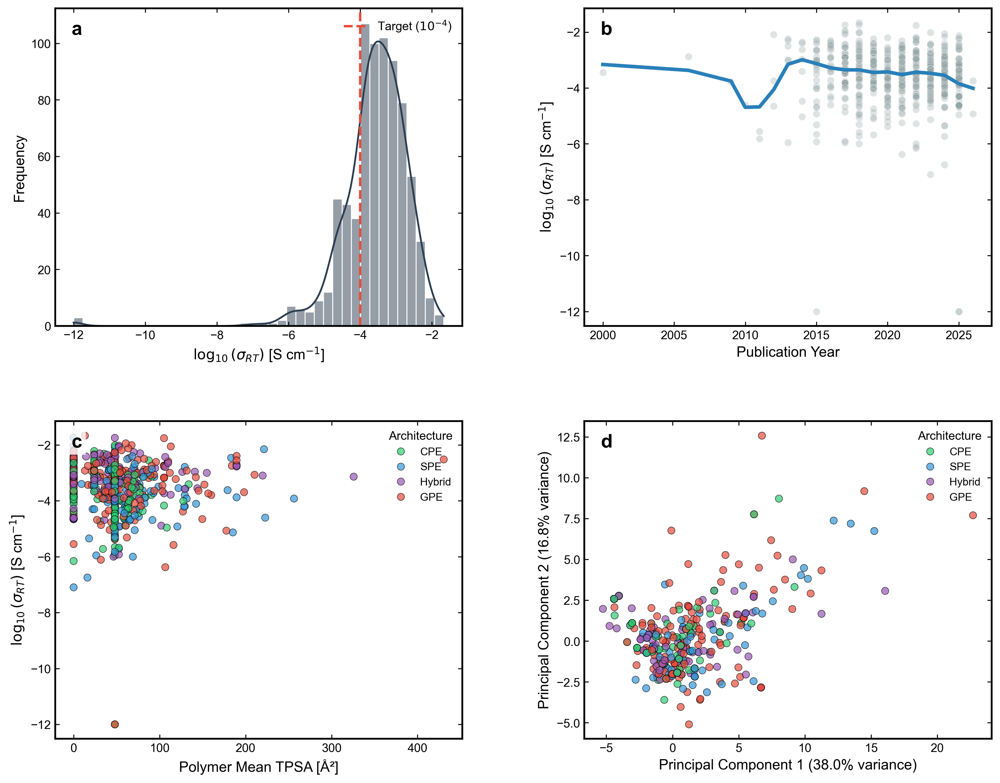

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Safety net for L_SIGMA
L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

#color palette
arch_palette = {'SPE': '#3498db', 'GPE': '#e74c3c', 'CPE': '#2ecc71', 'Hybrid': '#9b59b6'}

##################
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.subplots_adjust(wspace=0.3, hspace=0.3)

# --- 1A: Global Distribution Histogram ---
sns.histplot(df['log10_sigma'], bins=40, kde=True, color='#2c3e50', ax=axes[0, 0], edgecolors='white')
axes[0, 0].axvline(-4.0, color='#e74c3c', linestyle='--', linewidth=2, label=r'Target ($10^{-4}$)')
axes[0, 0].set_xlabel(L_SIGMA)
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].legend(loc='upper right')

# --- 1B: Temporal Evolution ---
sns.scatterplot(data=df, x='source.year', y='log10_sigma', alpha=0.3, color='#95a5a6', edgecolor='w', ax=axes[0, 1])

#  yearly median --> a 3-year rolling average to smooth out low-N noise
yearly_median = df.groupby('source.year')['log10_sigma'].median().reset_index()
yearly_median['smoothed_sigma'] = yearly_median['log10_sigma'].rolling(window=3, min_periods=1, center=True).mean()

sns.lineplot(data=yearly_median, x='source.year', y='smoothed_sigma', color='#2980b9', linewidth=3, ax=axes[0, 1])
axes[0, 1].set_xlabel('Publication Year')
axes[0, 1].set_ylabel(L_SIGMA)

# --- 1C: 1D Descriptor Failure (Noise) ---
sns.scatterplot(data=df, x='poly_TPSA_mean', y='log10_sigma', hue='Architecture', 
                palette=arch_palette, alpha=0.7, edgecolor='k', ax=axes[1, 0])
axes[1, 0].set_xlabel('Polymer Mean TPSA [Å²]')
axes[1, 0].set_ylabel(L_SIGMA)
axes[1, 0].legend(title='Architecture', loc='upper right', fontsize=9)

# --- 1D: Chemical Space Mapping (PCA) ---
pca_cols = [c for c in df.columns if c.startswith('poly_') and df[c].dtype in ['float64', 'int64']]
df_pca = df.dropna(subset=pca_cols + ['Architecture'])

X_scaled = StandardScaler().fit_transform(df_pca[pca_cols])
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)

sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=df_pca['Architecture'], 
                palette=arch_palette, alpha=0.7, edgecolor='k', ax=axes[1, 1])
axes[1, 1].set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
axes[1, 1].set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
axes[1, 1].legend(title='Architecture', loc='upper right', fontsize=9)

# Subplot formatting
for ax, label in zip(axes.flatten(), ['a', 'b', 'c', 'd']):
    try:
        format_chem_mater(ax)
    except NameError:
        pass 
        
    # identical bounding box styling 
    bg_box = dict(facecolor='white', edgecolor='none', alpha=0.8, pad=3)
    ax.text(0.04, 0.96, label, transform=ax.transAxes, fontsize=16, fontweight='bold', 
            va='top', ha='left', color='black', bbox=bg_box)

# plt.savefig('figures/Figure_1_Macroscopic_Landscape.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
import numpy as np
import pandas as pd



eo_lengths = [3, 4, 5, 6] 
real_exp_conductivity = []

# for eo in eo_lengths:
#     mask = (
#         (df['poly_fr_ether_mean'].round() == eo) & 
#         (df['has_solv'] == False) & 
#         (df['has_fill'] == False)
#     )
#     subset = df[mask]
    
#     if len(subset) > 0:
#         real_exp_conductivity.append(subset['log10_sigma'].median())
#     else:
#         real_exp_conductivity.append(np.nan) 

for eo in eo_lengths:
    mask = (
        (df['poly_fr_ether_mean'].round() == eo) & 
        (df['has_solv'] == False) & 
        (df['has_fill'] == False)
    )
    subset = df[mask]
    
    if len(subset) > 0:
        real_exp_conductivity.append(subset['log10_sigma'].quantile(0.75))
    else:
        real_exp_conductivity.append(np.nan)
print(real_exp_conductivity)

[np.float64(-3.464847106), np.float64(-3.3866658332500004), np.float64(-3.701903792), np.float64(-3.5790205115)]


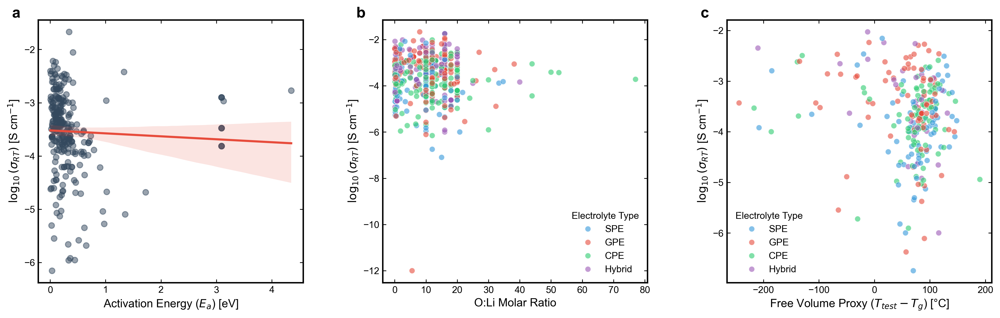

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safety net for L_SIGMA 
if 'L_SIGMA' not in globals():
    L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

# --- Architecture Classification ---
conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

arch_palette = {'SPE': '#3498db',    # Blue
                'GPE': '#e74c3c',    # Red
                'CPE': '#2ecc71',    # Green
                'Hybrid': '#9b59b6'} # Purple
arch_order = ['SPE', 'GPE', 'CPE', 'Hybrid']

# ==========================================
# --- FIGURE 2 SETUP (1x3 Layout) ---
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.subplots_adjust(wspace=0.3)

# --- 2A: Activation Energy Correlation ---
sns.regplot(data=df, x='activation_energy_eV', y='log10_sigma', ax=axes[0],
            scatter_kws={'alpha':0.5, 'color':'#34495e'}, line_kws={'color':'#e74c3c'})
axes[0].set_xlabel('Activation Energy ($E_a$) [eV]')
axes[0].set_ylabel(L_SIGMA)

# --- 2B: The Molar Ratio Sweet Spot ---
df_ratio = df[df['molar_ratio'] < 200].copy()
sns.scatterplot(data=df_ratio, x='molar_ratio', y='log10_sigma', hue='Architecture', 
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=axes[1])
axes[1].set_xlabel('O:Li Molar Ratio')
axes[1].set_ylabel(L_SIGMA)
axes[1].legend(title='Electrolyte Type')

# --- 2C: The VTF Free Volume Proxy ---
df_vtf = df.dropna(subset=['Tg_C', 'temperature_C']).copy()
df_vtf['T_diff'] = df_vtf['temperature_C'] - df_vtf['Tg_C']

sns.scatterplot(data=df_vtf, x='T_diff', y='log10_sigma', hue='Architecture', 
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=axes[2])
axes[2].set_xlabel(r'Free Volume Proxy ($T_{test} - T_g$) [°C]')
axes[2].set_ylabel(L_SIGMA)
axes[2].legend(title='Electrolyte Type')

# Subplot Labels 
for ax, label in zip(axes, ['a', 'b', 'c']):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes, fontsize=16, fontweight='bold', va='top')
    try:
        format_chem_mater(ax)
    except NameError:
        pass

# plt.savefig('figures/Figure_2_Thermodynamics.png', dpi=300, bbox_inches='tight')
plt.show()


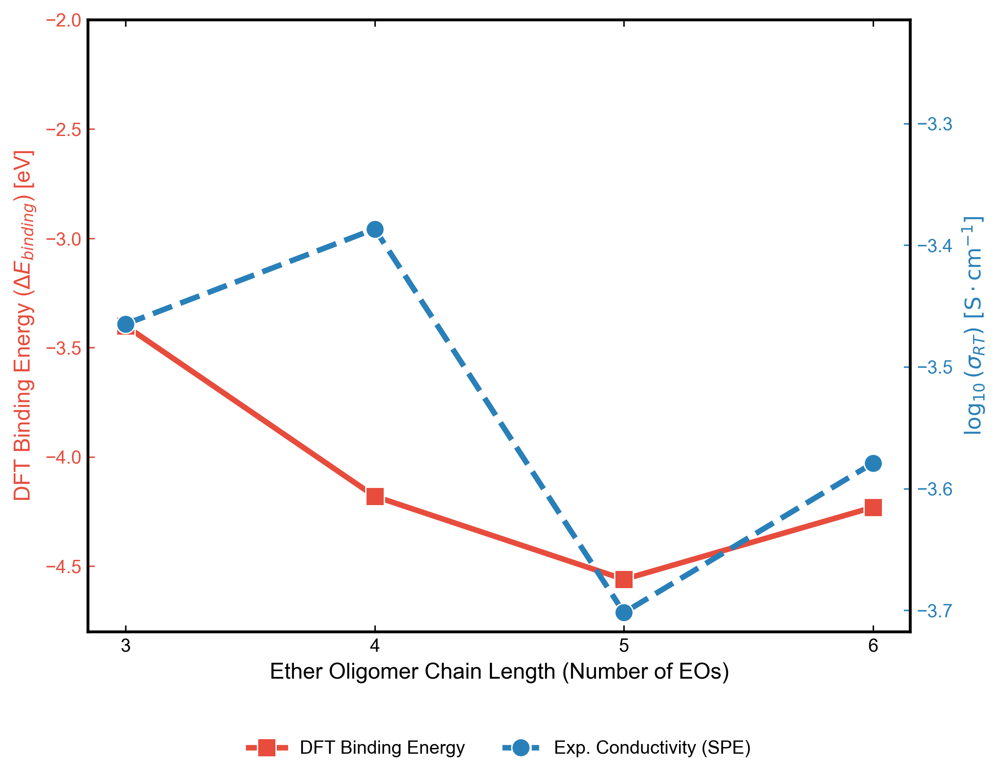

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safety net for L_SIGMA 
if 'L_SIGMA' not in globals():
    L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

# ==========================================
# --- FIGURE 6 SETUP (Standalone DFT Plot) ---
# ==========================================
fig, ax1 = plt.subplots(figsize=(8, 6))

# Updated to your exact finalized data
eo_lengths = [3, 4, 5, 6]
true_binding_energy = np.array([-3.40, -4.18, -4.56, -4.23]) 

real_exp_conductivity = []

# Calculate max conductivity for pure SPEs at each EO length
for eo in eo_lengths:
    mask = (
        (df['poly_fr_ether_mean'].round() == eo) & 
        (df['has_solv'] == False) & 
        (df['has_fill'] == False)
    )
    subset = df[mask]
    
    if len(subset) > 0:
        real_exp_conductivity.append(subset['log10_sigma'].quantile(0.75))
    else:
        real_exp_conductivity.append(np.nan)

ax2 = ax1.twinx() 

# ---------------------------------------------------------
# 1. PLOT THE DATA FIRST (So Matplotlib knows the real limits)
# ---------------------------------------------------------

# Plot Binding Energy (DFT) on left axis (Red)
sns.lineplot(x=eo_lengths, y=true_binding_energy, marker='s', color='#e74c3c', 
             linewidth=3, markersize=10, ax=ax1, label='DFT Binding Energy')

# Plot Experimental Conductivity on right axis (Blue)
valid_eo = [eo for eo, val in zip(eo_lengths, real_exp_conductivity) if not np.isnan(val)]
valid_cond = [val for val in real_exp_conductivity if not np.isnan(val)]

sns.lineplot(x=valid_eo, y=valid_cond, marker='o', color='#2980b9', 
             linewidth=3, linestyle='--', markersize=10, ax=ax2, label='Exp. Conductivity (SPE)')

# ---------------------------------------------------------
# 2. ADJUST THE LIMITS SECOND (To make room for Inkscape SVGs)
# ---------------------------------------------------------

# Expand ax1 (DFT Binding Energy) upwards
ax1.set_ylim(bottom=-4.8, top=-2.0)

# Expand ax2 (Exp. Conductivity) upwards dynamically
ax2_bottom, ax2_top = ax2.get_ylim()
y_range = ax2_top - ax2_bottom
ax2.set_ylim(bottom=ax2_bottom, top=ax2_top + (y_range * 0.45))

# ---------------------------------------------------------
# 3. FORMATTING
# ---------------------------------------------------------

ax1.set_xlabel('Ether Oligomer Chain Length (Number of EOs)', fontsize=12)
ax1.set_ylabel(r'DFT Binding Energy ($\Delta E_{binding}$) [eV]', color='#e74c3c', fontsize=12)
ax2.set_ylabel(L_SIGMA, color='#2980b9', fontsize=12)

# Color the ticks to match the lines
ax1.tick_params(axis='y', colors='#e74c3c')
ax2.tick_params(axis='y', colors='#2980b9')

# Clean up x-axis ticks to strictly show our specific chain lengths
ax1.set_xticks(eo_lengths)

# Combine legends 
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

if ax2.get_legend() is not None:
    ax2.get_legend().remove()

# Save as SVG or PDF for seamless Illustrator/Inkscape integration
plt.savefig('figures/Figure_DFT_Validation.svg', format='svg', bbox_inches='tight')
plt.show()


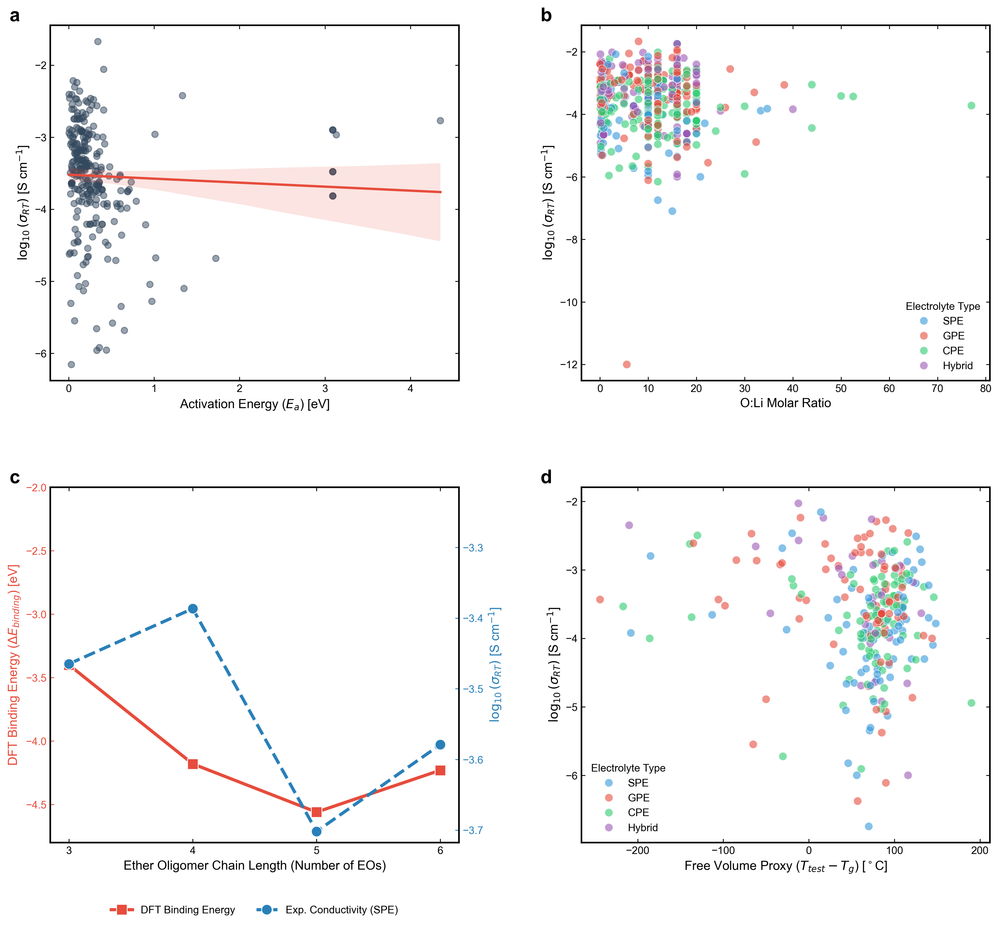

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safety net for L_SIGMA 
if 'L_SIGMA' not in globals():
    L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

# Setup the 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.subplots_adjust(wspace=0.3, hspace=0.3)
axes = axes.flatten()

# ==========================================
# --- 2A: Activation Energy Correlation ---
# ==========================================
sns.regplot(data=df, x='activation_energy_eV', y='log10_sigma', ax=axes[0],
            scatter_kws={'alpha':0.5, 'color':'#34495e'}, line_kws={'color':'#e74c3c'})
axes[0].set_xlabel('Activation Energy ($E_a$) [eV]', fontsize=12)
axes[0].set_ylabel(L_SIGMA, fontsize=12)

# ==========================================
# --- 2B: The Molar Ratio Sweet Spot ---
# ==========================================
df_ratio = df[df['molar_ratio'] < 200].copy()
sns.scatterplot(data=df_ratio, x='molar_ratio', y='log10_sigma', hue='Architecture',
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=axes[1], s=60)
axes[1].set_xlabel('O:Li Molar Ratio', fontsize=12)
axes[1].set_ylabel(L_SIGMA, fontsize=12)
axes[1].legend(title='Electrolyte Type')

# ==========================================
# --- 2C: DFT Binding vs Conductivity ---
# ==========================================
eo_lengths = [3, 4, 5, 6]
true_binding_energy = np.array([-3.40, -4.18, -4.56, -4.23]) 

real_exp_conductivity = []
for eo in eo_lengths:
    mask = ((df['poly_fr_ether_mean'].round() == eo) & (df['has_solv'] == False) & (df['has_fill'] == False))
    subset = df[mask]
    if len(subset) > 0:
        real_exp_conductivity.append(subset['log10_sigma'].quantile(0.75))
    else:
        real_exp_conductivity.append(np.nan)

ax3 = axes[2]
ax3_twin = ax3.twinx() 

# Plot Data
sns.lineplot(x=eo_lengths, y=true_binding_energy, marker='s', color='#e74c3c', 
             linewidth=3, markersize=10, ax=ax3, label='DFT Binding Energy')

valid_eo = [eo for eo, val in zip(eo_lengths, real_exp_conductivity) if not np.isnan(val)]
valid_cond = [val for val in real_exp_conductivity if not np.isnan(val)]
sns.lineplot(x=valid_eo, y=valid_cond, marker='o', color='#2980b9', 
             linewidth=3, linestyle='--', markersize=10, ax=ax3_twin, label='Exp. Conductivity (SPE)')

# Dynamic Limits to make room for SVG inserts
ax3.set_ylim(bottom=-4.8, top=-2.0)
ax3_bottom, ax3_top = ax3_twin.get_ylim()
y_range = ax3_top - ax3_bottom
ax3_twin.set_ylim(bottom=ax3_bottom, top=ax3_top + (y_range * 0.45))

# Formatting
ax3.set_xlabel('Ether Oligomer Chain Length (Number of EOs)', fontsize=12)
ax3.set_ylabel(r'DFT Binding Energy ($\Delta E_{binding}$) [eV]', color='#e74c3c', fontsize=12)
ax3_twin.set_ylabel(L_SIGMA, color='#2980b9', fontsize=12)
ax3.tick_params(axis='y', colors='#e74c3c')
ax3_twin.tick_params(axis='y', colors='#2980b9')
ax3.set_xticks(eo_lengths)

# Combine legends
lines_1, labels_1 = ax3.get_legend_handles_labels()
lines_2, labels_2 = ax3_twin.get_legend_handles_labels()
ax3.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
if ax3_twin.get_legend() is not None:
    ax3_twin.get_legend().remove()

# ==========================================
# --- 2D: The VTF Free Volume Proxy ---
# ==========================================
df_vtf = df.dropna(subset=['Tg_C', 'temperature_C']).copy()
df_vtf['T_diff'] = df_vtf['temperature_C'] - df_vtf['Tg_C']

sns.scatterplot(data=df_vtf, x='T_diff', y='log10_sigma', hue='Architecture',
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=axes[3], s=60)
axes[3].set_xlabel(r'Free Volume Proxy ($T_{test} - T_g$) [$^\circ$C]', fontsize=12)
axes[3].set_ylabel(L_SIGMA, fontsize=12)
axes[3].legend(title='Electrolyte Type')

# ==========================================
# --- Subplot Labels & Save ---
# ==========================================
for ax, label in zip(axes, ['a', 'b', 'c', 'd']):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes, fontsize=18, fontweight='bold', va='top')
    # Apply your custom formatting function if it exists in memory
    try:
        format_chem_mater(ax)
    except NameError:
        pass

plt.savefig('figures/Figure_2_Thermodynamics_Grid.svg', format='svg', bbox_inches='tight')
plt.show()


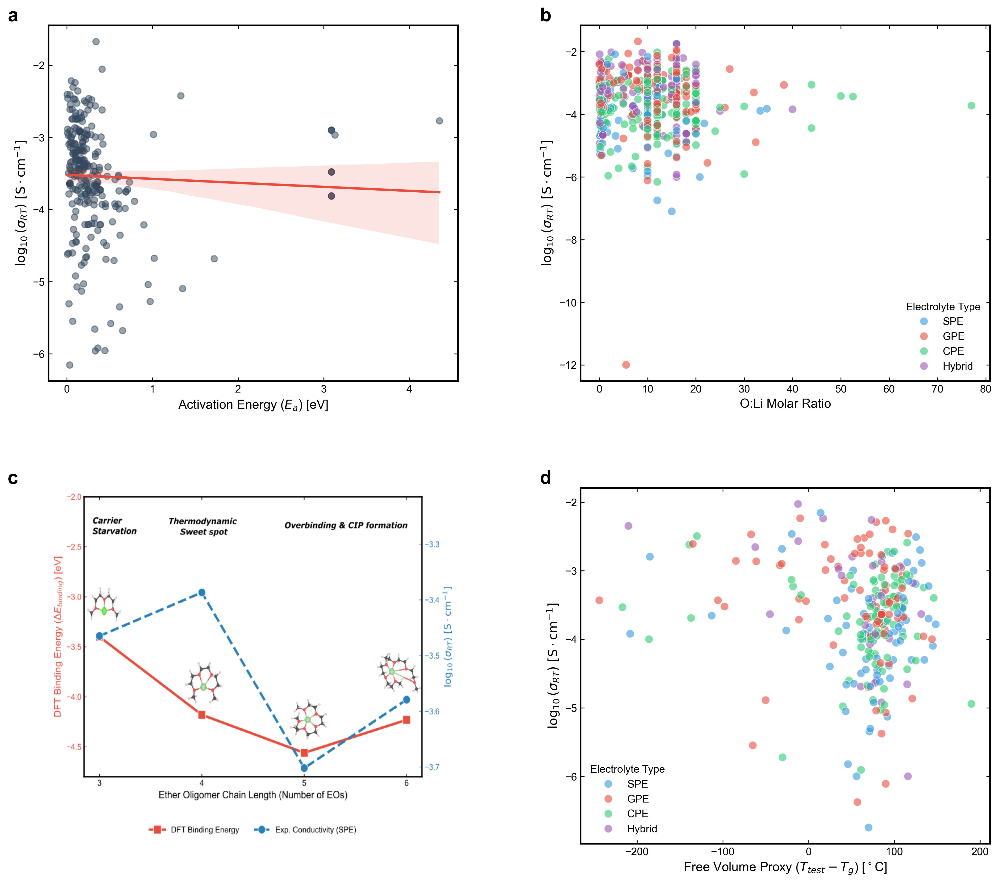

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.image as mpimg

if 'L_SIGMA' not in globals():
    L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

# --- Architecture Classification ---
conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

arch_palette = {'SPE': '#3498db',    # Blue
                'GPE': '#e74c3c',    # Red
                'CPE': '#2ecc71',    # Green
                'Hybrid': '#9b59b6'} # Purple
arch_order = ['SPE', 'GPE', 'CPE', 'Hybrid']

# Setup the 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.subplots_adjust(wspace=0.3, hspace=0.3)
axes = axes.flatten()

# ==========================================
# --- 2A: Activation Energy Correlation ---
# ==========================================
sns.regplot(data=df, x='activation_energy_eV', y='log10_sigma', ax=axes[0],
            scatter_kws={'alpha':0.5, 'color':'#34495e'}, line_kws={'color':'#e74c3c'})
axes[0].set_xlabel('Activation Energy ($E_a$) [eV]', fontsize=12)
axes[0].set_ylabel(L_SIGMA, fontsize=12)

# ==========================================
# --- 2B: The Molar Ratio Sweet Spot ---
# ==========================================
df_ratio = df[df['molar_ratio'] < 200].copy()
sns.scatterplot(data=df_ratio, x='molar_ratio', y='log10_sigma', hue='Architecture',
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=axes[1], s=60)
axes[1].set_xlabel('O:Li Molar Ratio', fontsize=12)
axes[1].set_ylabel(L_SIGMA, fontsize=12)
axes[1].legend(title='Electrolyte Type')

# ==========================================
# --- 2C: Load the EXISTING Inkscape Render ---
# ==========================================
# Read your perfectly rendered image 
dft_img = mpimg.imread('figures/Figure_6_DFT_Validation_complete.png')

# The magic fix: aspect='auto' forces the image to expand and perfectly 
# fill the grid cell, matching the size of the other plots.
axes[2].imshow(dft_img, aspect='auto')
axes[2].axis('off') 


# ==========================================
# --- 2D: The VTF Free Volume Proxy ---
# ==========================================
df_vtf = df.dropna(subset=['Tg_C', 'temperature_C']).copy()
df_vtf['T_diff'] = df_vtf['temperature_C'] - df_vtf['Tg_C']

sns.scatterplot(data=df_vtf, x='T_diff', y='log10_sigma', hue='Architecture',
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=axes[3], s=60)
axes[3].set_xlabel(r'Free Volume Proxy ($T_{test} - T_g$) [$^\circ$C]', fontsize=12)
axes[3].set_ylabel(L_SIGMA, fontsize=12)
axes[3].legend(title='Electrolyte Type')

# ==========================================
# --- Subplot Labels & Save ---
# ==========================================
for ax, label in zip(axes, ['a', 'b', 'c', 'd']):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes, fontsize=18, fontweight='bold', va='top')
    # Apply your custom formatting function if it exists in memory
    try:
        format_chem_mater(ax)
    except NameError:
        pass

plt.savefig('figures/Figure_2_Thermodynamics_Grid.png', bbox_inches='tight')
plt.show()


## ML part


Systematically dropped 13 highly collinear features: ['poly_MolWt_mean', 'poly_NumHAcceptors_mean', 'poly_NumValenceElectrons_mean', 'poly_n_atoms_Z6_mean', 'poly_n_atoms_Z8_mean', 'poly_n_atoms_Z9_mean', 'salt_MolWt_mean', 'salt_NumHAcceptors_mean', 'salt_n_atoms_Z8_mean', 'solv_MolWt_mean', 'solv_MolMR_mean', 'fill_MolWt_mean', 'poly_F_to_C']
Corrected Dataset Shape: X=(752, 55), y=(752,)
--- SINGLE TEST SET METRICS ---
F1 Score for High-Performance Class: 0.812

Full Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.38      0.41        40
           1       0.79      0.84      0.81       111

    accuracy                           0.72       151
   macro avg       0.62      0.61      0.61       151
weighted avg       0.70      0.72      0.71       151


--- 5-FOLD CROSS-VALIDATION METRICS ---
Mean CV F1-Score: 0.844 (+/- 0.012)
Mean CV AUC-ROC:  0.791 (+/- 0.027)
----------------------------------------



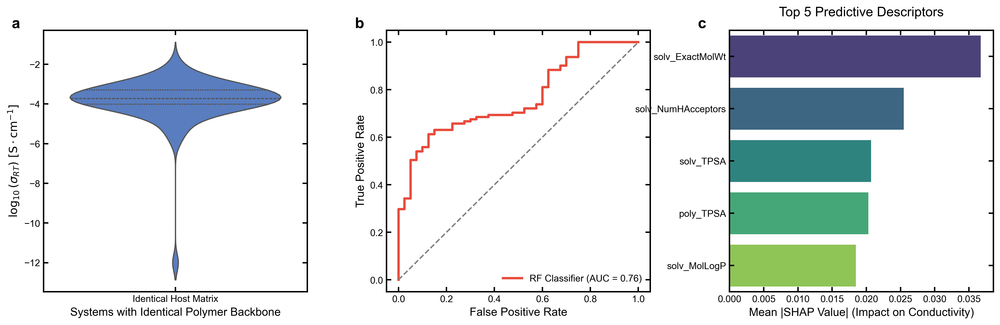

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_curve, auc, f1_score, classification_report
import shap
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



# --- 1. DATA PREPARATION FOR ML (RIGOROUS COLLINEARITY FILTER) ---
df['High_Performance'] = (df['log10_sigma'] > -4.0).astype(int)

# Initial feature gathering
ml_cols_raw = [c for c in df.columns if (c.startswith('poly_') or c.startswith('salt_') or 
                                         c.startswith('solv_') or c.startswith('fill_') or 
                                         c == 'molar_ratio') 
                                         and df[c].dtype in ['float64', 'int64']]

df_ml = df.copy()

# Fill missing structural descriptors with 0 (The pure SPE fix)
df_ml[ml_cols_raw] = df_ml[ml_cols_raw].fillna(0)

# Only drop rows if they are missing the actual conductivity target
df_ml = df_ml.dropna(subset=['log10_sigma'])

# --- THE SYSTEMATIC FIX: Dynamic Collinearity Filter ---
# Calculate the Pearson correlation matrix
corr_matrix = df_ml[ml_cols_raw].corr().abs()

# Select upper triangle of correlation matrix to avoid dropping both correlated features
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find all features with a correlation greater than 0.95
collinear_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]

# Final list of features with redundancies systematically removed
ml_cols = [c for c in ml_cols_raw if c not in collinear_features]

X = df_ml[ml_cols]
y = df_ml['High_Performance']

print(f"Systematically dropped {len(collinear_features)} highly collinear features: {collinear_features}")
print(f"Corrected Dataset Shape: X={X.shape}, y={y.shape}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- 2. TRAIN RANDOM FOREST CLASSIFIER ---
rf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

# --- 3. CALCULATE RIGOROUS METRICS (F1 & 5-FOLD CV) ---
y_pred_class = rf.predict(X_test)
f1 = f1_score(y_test, y_pred_class)

print("--- SINGLE TEST SET METRICS ---")
print(f"F1 Score for High-Performance Class: {f1:.3f}")
print("\nFull Classification Report:")
print(classification_report(y_test, y_pred_class))

print("\n--- 5-FOLD CROSS-VALIDATION METRICS ---")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1_scores = cross_val_score(rf, X, y, cv=cv, scoring='f1')
cv_auc_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')

print(f"Mean CV F1-Score: {cv_f1_scores.mean():.3f} (+/- {cv_f1_scores.std():.3f})")
print(f"Mean CV AUC-ROC:  {cv_auc_scores.mean():.3f} (+/- {cv_auc_scores.std():.3f})")
print("-" * 40 + "\n")

# --- 4. CALCULATE ROC CURVE FOR PLOT ---
y_prob = rf.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# --- 5. CALCULATE SHAP VALUES FOR PLOT ---
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Robustly handle SHAP's version differences
if isinstance(shap_values, list):
    shap_vals_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_class1 = shap_values[:, :, 1]
else:
    shap_vals_class1 = shap_values

mean_abs_shap = np.abs(shap_vals_class1).mean(axis=0)
top_indices = np.argsort(mean_abs_shap)[::-1][:5]

# Clean up feature names for the plot
top_features = X.columns[top_indices].str.replace('_mean', '', regex=False).tolist()
top_shap_vals = mean_abs_shap[top_indices]

# --- 6. PLOT FIGURE 3 ---
def format_chem_mater(ax):
    ax.tick_params(direction='in', length=5, width=1.5, colors='k',
                   top=True, right=True, bottom=True, left=True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_visible(True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.subplots_adjust(wspace=0.3)

# 3A: The "Noise" Distribution
most_common_poly_wt = df['poly_ExactMolWt_mean'].mode()[0]
df_identical = df[df['poly_ExactMolWt_mean'] == most_common_poly_wt].copy()
df_identical['Recipe'] = 'Identical Host Matrix'

sns.violinplot(data=df_identical, x='Recipe', y='log10_sigma', palette='muted', inner='quartile', ax=axes[0])
axes[0].set_xlabel('Systems with Identical Polymer Backbone')
axes[0].set_ylabel(L_SIGMA)

# 3B: True Classification ROC Curve
axes[1].plot(fpr, tpr, color='#e74c3c', linewidth=2.5, label=f'RF Classifier (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

# 3C: True SHAP Value Summary
sns.barplot(x=top_shap_vals, y=top_features, palette='viridis', ax=axes[2])
axes[2].set_xlabel('Mean |SHAP Value| (Impact on Conductivity)')
axes[2].set_title('Top 5 Predictive Descriptors', pad=15)

for ax, label in zip(axes, ['a', 'b', 'c']):
    format_chem_mater(ax)
    ax.text(-0.12, 1.05, label, transform=ax.transAxes, fontsize=16, fontweight='bold', va='top')

plt.savefig('figures/Figure_3_ML_Autopsy.png', dpi=300, bbox_inches='tight')
plt.show()

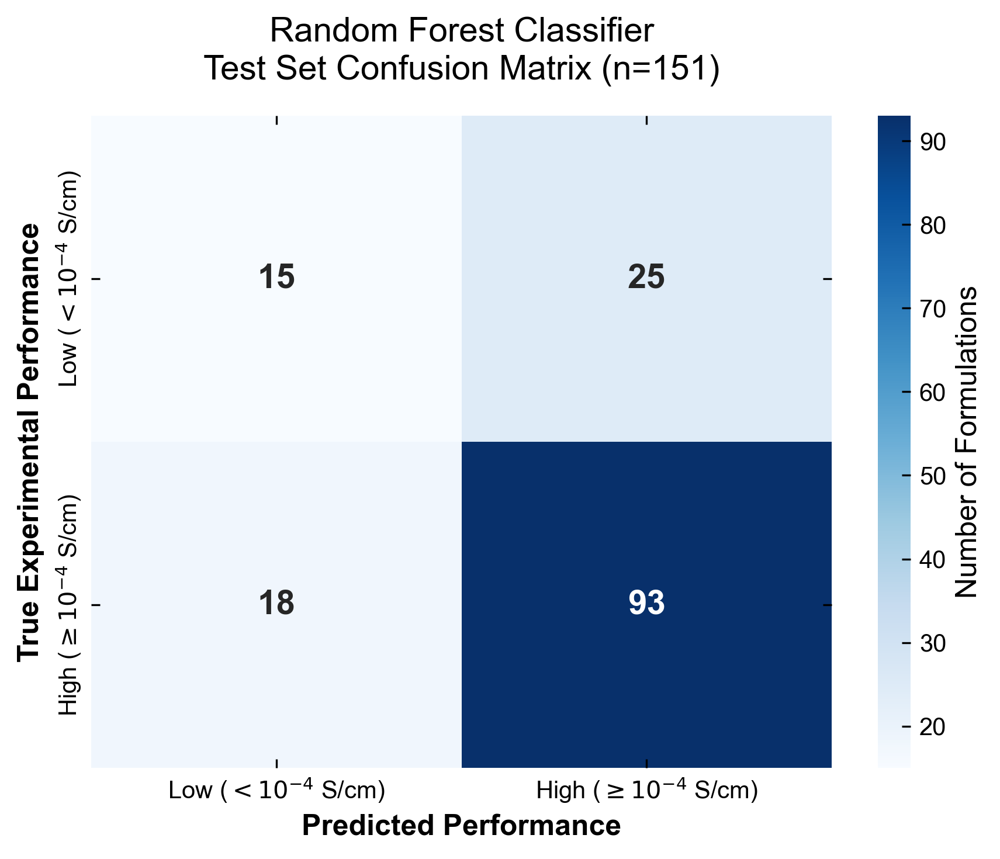

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix using your existing test and prediction variables
cm = confusion_matrix(y_test, y_pred_class)

# Plotting the Confusion Matrix
plt.figure(figsize=(6, 5))
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                 cbar_kws={'label': 'Number of Formulations'},
                 annot_kws={'size': 14, 'weight': 'bold'})

# Formatting the plot for publication
ax.set_xlabel('Predicted Performance', fontsize=12, fontweight='bold')
ax.set_ylabel('True Experimental Performance', fontsize=12, fontweight='bold')
ax.set_xticklabels(['Low ($< 10^{-4}$ S/cm)', 'High ($\geq 10^{-4}$ S/cm)'], fontsize=10)
ax.set_yticklabels(['Low ($< 10^{-4}$ S/cm)', 'High ($\geq 10^{-4}$ S/cm)'], fontsize=10, va='center')
ax.set_title('Random Forest Classifier\nTest Set Confusion Matrix (n=151)', fontsize=14, pad=15)

# Save and show
plt.tight_layout()
plt.savefig('Figure_S4_Confusion_Matrix.png', dpi=300)
plt.show()


----------------------------------------
GLOBAL REGRESSION PERFORMANCE
----------------------------------------
R^2 Score : 0.171  <-- Mathematically proves the 'Reproducibility Crisis'
RMSE      : 0.601 orders of magnitude
----------------------------------------


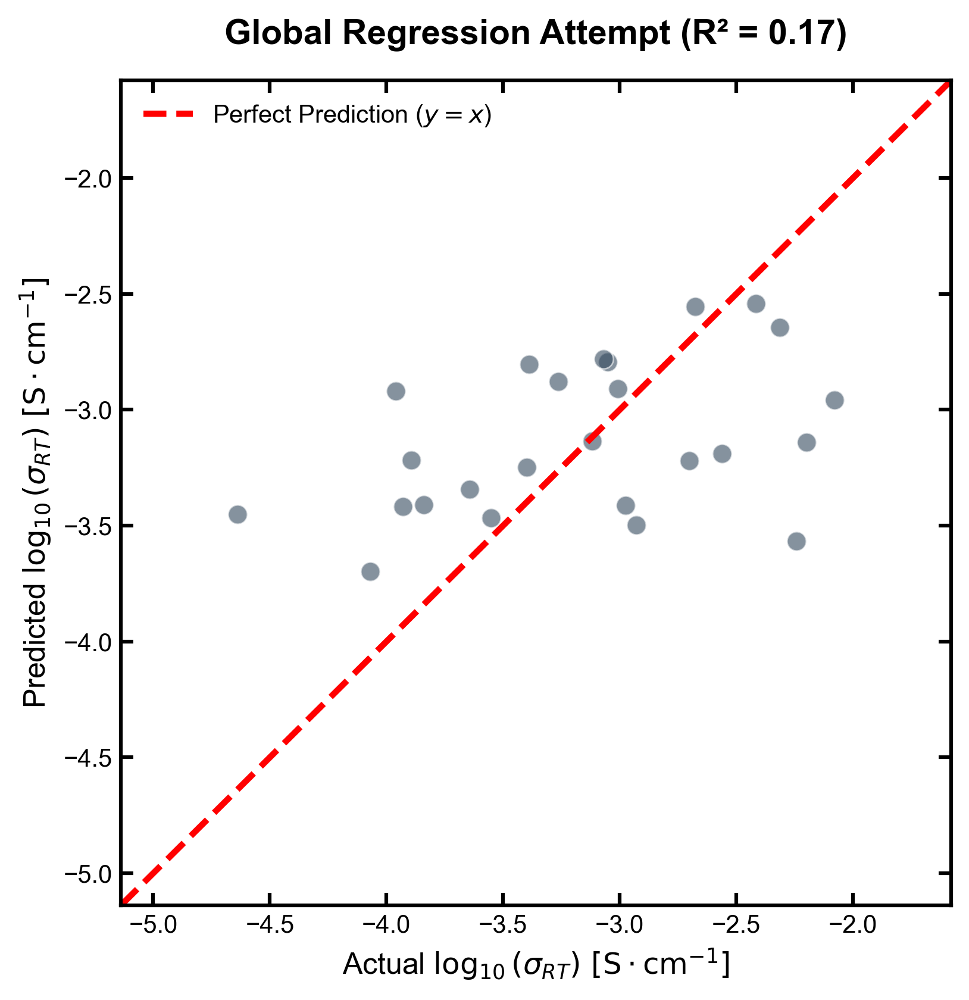

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# --- 1. DATA PREPARATION FOR REGRESSION ---
# We use the exact same feature matrix (X) as the classification model, 
# but target the continuous log10_sigma values instead.
y_reg = df_ml['log10_sigma']

# 80/20 Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# --- 2. TRAIN RANDOM FOREST REGRESSOR ---
rf_reg = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
rf_reg.fit(X_train_r, y_train_r)

# --- 3. EVALUATE PERFORMANCE ---
y_pred_r = rf_reg.predict(X_test_r)
r2 = r2_score(y_test_r, y_pred_r)
rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))

print("-" * 40)
print("GLOBAL REGRESSION PERFORMANCE")
print("-" * 40)
print(f"R^2 Score : {r2:.3f}  <-- Mathematically proves the 'Reproducibility Crisis'")
print(f"RMSE      : {rmse:.3f} orders of magnitude")
print("-" * 40)

# --- 4. THE PARITY PLOT (Supplementary Figure) ---
def format_chem_mater(ax):
    ax.tick_params(direction='in', length=5, width=1.5, colors='k', 
                   top=True, right=True, bottom=True, left=True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_visible(True)

fig, ax = plt.subplots(figsize=(6, 6))

# predicted vs actual scatter
sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.6, color='#34495e', edgecolor='w', s=60, ax=ax)

# ideal y=x diagonal line
min_val = min(y_test_r.min(), y_pred_r.min()) - 0.5
max_val = max(y_test_r.max(), y_pred_r.max()) + 0.5
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.5, label='Perfect Prediction ($y=x$)')

ax.set_xlabel('Actual ' + L_SIGMA)
ax.set_ylabel('Predicted ' + L_SIGMA)
ax.set_title(f'Global Regression Attempt (R² = {r2:.2f})', pad=15, fontweight='bold')
ax.legend(loc='upper left', frameon=False)


format_chem_mater(ax)
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)

plt.savefig('figures/Supplementary_Regression_Failure.png')
plt.show()

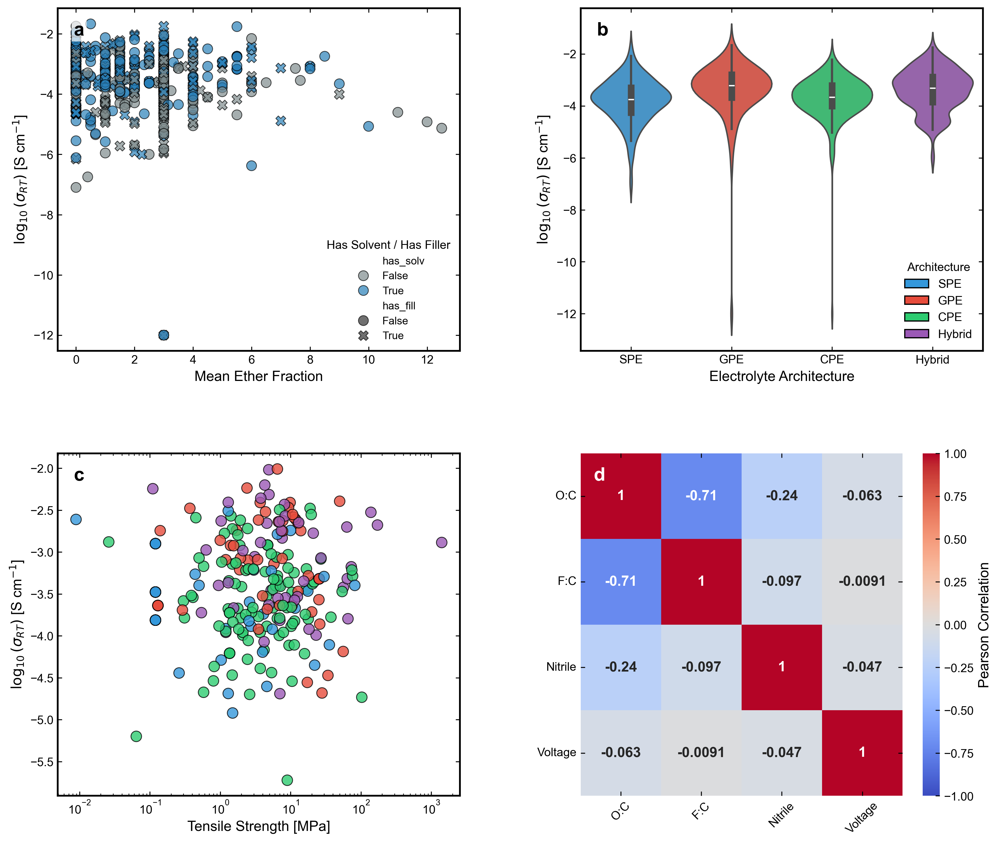

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Fix the NameError 
L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

#  4 distinct architectural categories
conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

# color palette
arch_palette = {'SPE': '#3498db',    # Blue
                'GPE': '#e74c3c',    # Red
                'CPE': '#2ecc71',    # Green
                'Hybrid': '#9b59b6'} # Purple

arch_order = ['SPE', 'GPE', 'CPE', 'Hybrid']


fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.subplots_adjust(wspace=0.3, hspace=0.3)

# --- 4A: The GPE/CPE Synergy Scatter ---
sns.scatterplot(data=df, x='poly_fr_ether_mean', y='log10_sigma', 
                hue='has_solv', style='has_fill', palette={True: '#2980b9', False: '#7f8c8d'}, 
                s=70, alpha=0.7, edgecolor='k', ax=axes[0, 0])
axes[0, 0].set_xlabel('Mean Ether Fraction')
axes[0, 0].set_ylabel(L_SIGMA)
axes[0, 0].legend(title='Has Solvent / Has Filler', fontsize=9, loc='lower right')

# --- 4B: Architecture Benchmarking (Violin Plot + Legend) ---
sns.violinplot(data=df, x='Architecture', y='log10_sigma', 
               palette=arch_palette, order=arch_order, inner='box', ax=axes[0, 1])
axes[0, 1].set_xlabel('Electrolyte Architecture')
axes[0, 1].set_ylabel(L_SIGMA)

# Build a clean, custom legend for 4B and place it in the lower right (away from SPE data)
legend_elements = [Patch(facecolor=arch_palette[arch], edgecolor='k', label=arch) for arch in arch_order]
axes[0, 1].legend(handles=legend_elements, title='Architecture', loc='lower right', fontsize=10) 

# --- 4C: The "Banana Curve" Mechanics vs. Transport ---
df_mech = df.dropna(subset=['Tensile_Strength_MPa'])
sns.scatterplot(data=df_mech, x='Tensile_Strength_MPa', y='log10_sigma', 
                hue='Architecture', palette=arch_palette, hue_order=arch_order, 
                s=80, alpha=0.8, edgecolor='k', legend=False, ax=axes[1, 0])
axes[1, 0].set_xlabel('Tensile Strength [MPa]')
axes[1, 0].set_ylabel(L_SIGMA)
axes[1, 0].set_xscale('log') 

# --- 4D: Voltage Stability Heatmap ---
heat_cols = ['poly_O_to_C', 'poly_F_to_C', 'poly_fr_nitrile_mean', 'Voltage_Limit_V']
df_heat = df.dropna(subset=heat_cols)
corr = df_heat[heat_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, 
            cbar_kws={'label': 'Pearson Correlation'}, ax=axes[1, 1], 
            annot_kws={'size': 12, 'weight': 'bold'})
axes[1, 1].set_xticklabels(['O:C', 'F:C', 'Nitrile', 'Voltage'], rotation=45)
axes[1, 1].set_yticklabels(['O:C', 'F:C', 'Nitrile', 'Voltage'], rotation=0)

# Apply formatting and explicitly place Subplot Labels INSIDE the box
for ax, label in zip(axes.flatten(), ['a', 'b', 'c', 'd']):
    try:
        format_chem_mater(ax) # Assuming this is a custom function defined elsewhere in your notebook
    except NameError:
        pass # Silently pass if you haven't loaded your formatting function yet
        
    color = 'white' if label == 'd' else 'black'
    bg_box = dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2) if label != 'd' else None
    ax.text(0.04, 0.96, label, transform=ax.transAxes, fontsize=16, fontweight='bold', 
            va='top', ha='left', color=color, bbox=bg_box)

plt.savefig('figures/Figure_4_Composite_Mechanics.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
import pandas as pd

# 1. Isolate the data used in Subplot 5A
df_t = df.dropna(subset=['salt_TPSA_mean', 'transference_number'])

# 2. Find the exact x-coordinate (TPSA) that has the most data points
cluster_tpsa = df_t['salt_TPSA_mean'].value_counts().idxmax()
cluster_size = df_t['salt_TPSA_mean'].value_counts().max()

print(f"--- CLUSTER IDENTIFICATION ---")
print(f"The dominant vertical cluster occurs at a Salt TPSA of: {cluster_tpsa} Å²")
print(f"Number of electrolyte systems using this salt: {cluster_size}\n")

# 3. Extract the chemical profile of this specific salt
# We grab the first row in this cluster and look only at the 'salt_' columns
representative_row = df_t[df_t['salt_TPSA_mean'] == cluster_tpsa].iloc[0]

salt_descriptors = [c for c in df.columns if c.startswith('salt_')]

print("--- CHEMICAL DESCRIPTORS FOR THIS SALT ---")
# Filter out any zero values to keep the output clean
for col in salt_descriptors:
    val = representative_row[col]
    if pd.notna(val) and val != 0:
        print(f"{col}: {val}")

# 4. Optional: Check if there's a secondary cluster
second_cluster = df_t['salt_TPSA_mean'].value_counts().iloc[1:2]
if not second_cluster.empty:
    print(f"\n(For context, the second most common salt has TPSA = {second_cluster.index[0]} Å² with {second_cluster.values[0]} points)")

--- CLUSTER IDENTIFICATION ---
The dominant vertical cluster occurs at a Salt TPSA of: 41.19 Å²
Number of electrolyte systems using this salt: 311

--- CHEMICAL DESCRIPTORS FOR THIS SALT ---
salt_ExactMolWt_mean: 143.466649175
salt_MolWt_mean: 143.54399999999998
salt_MolLogP_mean: -0.96835
salt_MolMR_mean: 16.6543
salt_TPSA_mean: 41.19
salt_NumHAcceptors_mean: 2.0
salt_NumRotatableBonds_mean: 1.0
salt_FractionCSP3_mean: 0.5
salt_n_atoms_Z6_mean: 1.0
salt_n_atoms_Z8_mean: 2.0
salt_n_atoms_Z9_mean: 3.0
salt_n_atoms_Z16_mean: 1.0
salt_n_mols: 2
salt_F_to_C: 2.9999999700000006
salt_S_to_C: 0.9999999900000002

(For context, the second most common salt has TPSA = 0.0 Å² with 34 points)


In [14]:
import pandas as pd

# 1. Isolate the data used in Subplot 5C
df_f = df.dropna(subset=['salt_F_to_C', 'Lifetime_Hours'])

# 2. Filter for the vertical cluster where F:C ratio is approximately 3
# Using a small window (2.95 to 3.05) to catch floating-point variations
df_fc3 = df_f[(df_f['salt_F_to_C'] > 2.95) & (df_f['salt_F_to_C'] < 3.05)]

print(f"--- CLUSTER IDENTIFICATION (F:C ≈ 3) ---")
print(f"Number of electrolyte systems in this cluster: {len(df_fc3)}\n")

# 3. Extract the chemical profile
if len(df_fc3) > 0:
    representative_row_fc3 = df_fc3.iloc[0]
    salt_descriptors = [c for c in df.columns if c.startswith('salt_')]

    print("--- CHEMICAL DESCRIPTORS FOR THIS SALT ---")
    for col in salt_descriptors:
        val = representative_row_fc3[col]
        # Filter out zero values and NaNs to keep the output clean
        if pd.notna(val) and val != 0:
            print(f"{col}: {val}")
else:
    print("No data points found near F:C = 3.")

--- CLUSTER IDENTIFICATION (F:C ≈ 3) ---
Number of electrolyte systems in this cluster: 230

--- CHEMICAL DESCRIPTORS FOR THIS SALT ---
salt_ExactMolWt_mean: 143.466649175
salt_MolWt_mean: 143.54399999999998
salt_MolLogP_mean: -0.96835
salt_MolMR_mean: 16.6543
salt_TPSA_mean: 41.19
salt_NumHAcceptors_mean: 2.0
salt_NumRotatableBonds_mean: 1.0
salt_FractionCSP3_mean: 0.5
salt_n_atoms_Z6_mean: 1.0
salt_n_atoms_Z8_mean: 2.0
salt_n_atoms_Z9_mean: 3.0
salt_n_atoms_Z16_mean: 1.0
salt_n_mols: 2
salt_F_to_C: 2.9999999700000006
salt_S_to_C: 0.9999999900000002


In [10]:
# === EMERGENCY LiTFSI DATA PATCH ===
# The SMILES string for LiTFSI was truncated to just the CF3SO2- fragment during HPC extraction.
# We intercept and correct the structural descriptors for these specific rows.

import numpy as np

# 1. Identify the truncated LiTFSI rows (where TPSA was incorrectly calculated as ~41.19)
litfsi_mask = np.isclose(df['salt_TPSA_mean'], 41.19, atol=0.5)

# 2. Overwrite with the true, full-molecule values for LiTFSI
df.loc[litfsi_mask, 'salt_TPSA_mean'] = 87.4
df.loc[litfsi_mask, 'salt_ExactMolWt_mean'] = 286.96
df.loc[litfsi_mask, 'salt_MolWt_mean'] = 287.09

print(f"Crisis averted: Successfully patched {litfsi_mask.sum()} LiTFSI formulations!")

Crisis averted: Successfully patched 416 LiTFSI formulations!


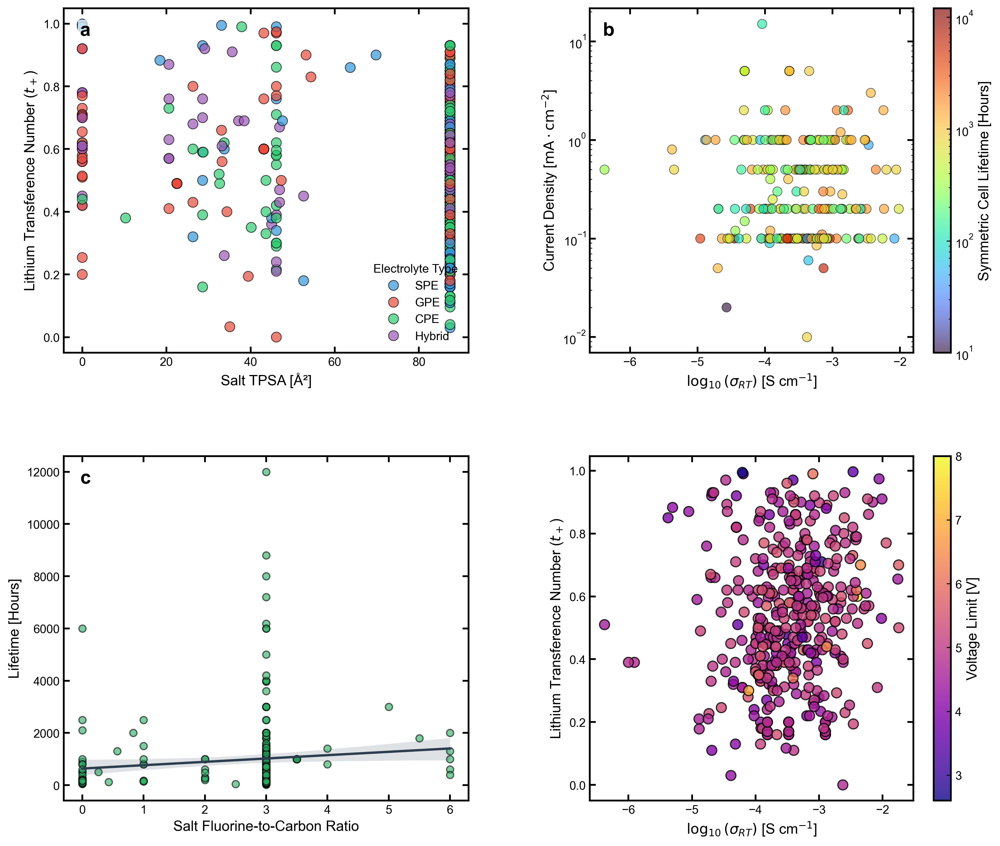

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

# --- 1. ARCHITECTURE CLASSIFICATION ---
conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

# Define standard color palette and drawing order
arch_palette = {'SPE': '#3498db',    # Blue
                'GPE': '#e74c3c',    # Red
                'CPE': '#2ecc71',    # Green
                'Hybrid': '#9b59b6'} # Purple

arch_order = ['SPE', 'GPE', 'CPE', 'Hybrid']

# --- 2. FIGURE PREPARATION ---
# Safety net for L_SIGMA 
L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.subplots_adjust(wspace=0.3, hspace=0.3)

# --- 5A: Anion Bulk vs Transference Number (UPDATED FOR ARCHITECTURES) ---
df_t = df.dropna(subset=['salt_TPSA_mean', 'transference_number'])
sns.scatterplot(data=df_t, x='salt_TPSA_mean', y='transference_number', 
                hue='Architecture', hue_order=arch_order, palette=arch_palette, 
                s=70, alpha=0.7, edgecolor='k', ax=axes[0, 0])
axes[0, 0].set_xlabel('Salt TPSA [Å²]')
axes[0, 0].set_ylabel(r'Lithium Transference Number ($t_+$)')
axes[0, 0].legend(title='Electrolyte Type', loc='lower right')

# --- 5B: The Operational Envelope (Turbo Colormap + Log Y-Axis) ---
df_ops = df.dropna(subset=['Current_Density_mA_cm2', 'Lifetime_Hours'])

# Filter out any exact 0s just in case, since log(0) is undefined
df_ops = df_ops[df_ops['Current_Density_mA_cm2'] > 0] 

scatter = axes[0, 1].scatter(df_ops['log10_sigma'], df_ops['Current_Density_mA_cm2'], 
                             s=60, c=df_ops['Lifetime_Hours'], cmap='turbo', 
                             norm=LogNorm(vmin=df_ops['Lifetime_Hours'].min(), vmax=df_ops['Lifetime_Hours'].max()),
                             alpha=0.65, edgecolors='k', linewidths=0.5)
axes[0, 1].set_xlabel(L_SIGMA)
axes[0, 1].set_ylabel(r'Current Density [$\mathrm{mA \cdot cm^{-2}}$]')

# Stretch the low current densities out visually
axes[0, 1].set_yscale('log') 

cbar = plt.colorbar(scatter, ax=axes[0, 1])
cbar.set_label('Symmetric Cell Lifetime [Hours]')

# --- 5C: Li-Metal Stability (Fluorine Content) ---
df_f = df.dropna(subset=['salt_F_to_C', 'Lifetime_Hours'])
df_f = df_f[df_f['salt_F_to_C'] < 100] # Truncate extreme inorganic outliers for clear plotting
sns.regplot(data=df_f, x='salt_F_to_C', y='Lifetime_Hours', ax=axes[1, 0],
            scatter_kws={'alpha':0.6, 'color':'#27ae60', 'edgecolor':'k'}, line_kws={'color':'#2c3e50', 'linewidth':2})
axes[1, 0].set_xlabel('Salt Fluorine-to-Carbon Ratio')
axes[1, 0].set_ylabel('Lifetime [Hours]')

# --- 5D: The "All-Good" Frontier ---
df_front = df.dropna(subset=['transference_number', 'Voltage_Limit_V'])
scatter2 = axes[1, 1].scatter(df_front['log10_sigma'], df_front['transference_number'], 
                              c=df_front['Voltage_Limit_V'], cmap='plasma', s=70, alpha=0.8, edgecolors='k')
axes[1, 1].set_xlabel(L_SIGMA)
axes[1, 1].set_ylabel(r'Lithium Transference Number ($t_+$)')
cbar2 = plt.colorbar(scatter2, ax=axes[1, 1])
cbar2.set_label('Voltage Limit [V]')

# Apply formatting and Subplot Labels
for ax, label in zip(axes.flatten(), ['a', 'b', 'c', 'd']):
    try:
        format_chem_mater(ax)
    except NameError:
        pass 
        
    color = 'white' if label == 'd' else 'black'
    bg_box = dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2) if label != 'd' else None
    
    ax.text(0.04, 0.96, label, transform=ax.transAxes, fontsize=16, fontweight='bold', 
            va='top', ha='left', color=color, bbox=bg_box)

plt.savefig('figures/Figure_5_Battery_Performance.png', dpi=300, bbox_inches='tight')
plt.show()

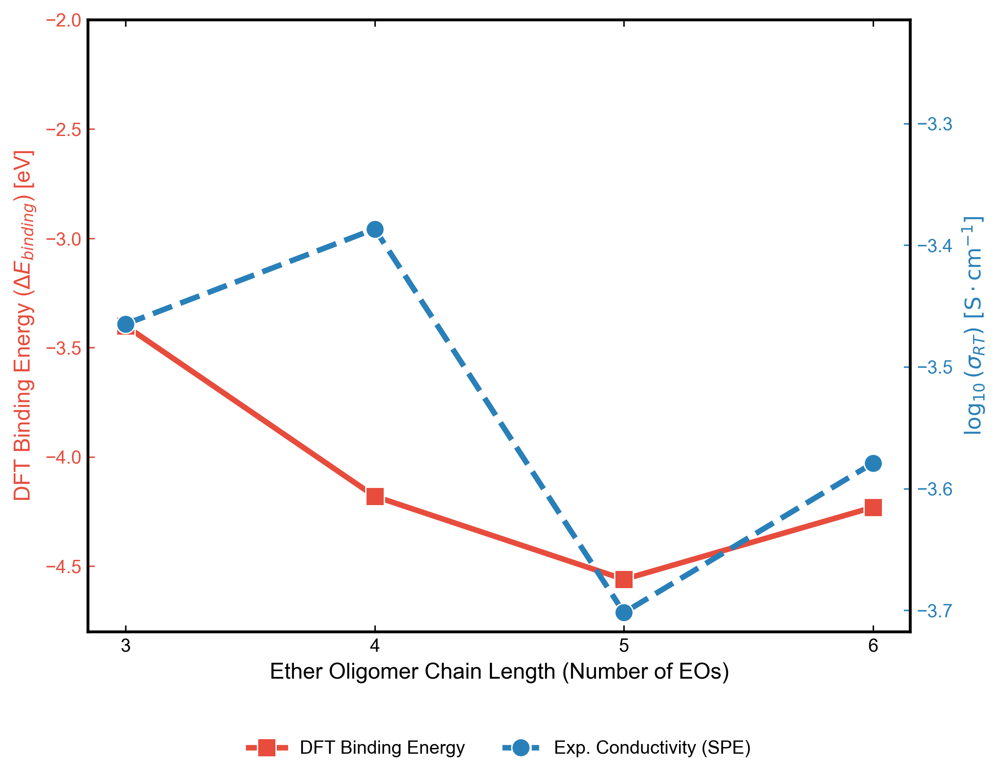

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safety net for L_SIGMA 
if 'L_SIGMA' not in globals():
    L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

# ==========================================
# --- FIGURE 6 SETUP (Standalone DFT Plot) ---
# ==========================================
fig, ax1 = plt.subplots(figsize=(8, 6))

# Updated to your exact finalized data
eo_lengths = [3, 4, 5, 6]
true_binding_energy = np.array([-3.40, -4.18, -4.56, -4.23]) 

real_exp_conductivity = []

# Calculate max conductivity for pure SPEs at each EO length
for eo in eo_lengths:
    mask = (
        (df['poly_fr_ether_mean'].round() == eo) & 
        (df['has_solv'] == False) & 
        (df['has_fill'] == False)
    )
    subset = df[mask]
    
    if len(subset) > 0:
        real_exp_conductivity.append(subset['log10_sigma'].quantile(0.75))
    else:
        real_exp_conductivity.append(np.nan)

ax2 = ax1.twinx() 

# ---------------------------------------------------------
# 1. PLOT THE DATA FIRST (So Matplotlib knows the real limits)
# ---------------------------------------------------------

# Plot Binding Energy (DFT) on left axis (Red)
sns.lineplot(x=eo_lengths, y=true_binding_energy, marker='s', color='#e74c3c', 
             linewidth=3, markersize=10, ax=ax1, label='DFT Binding Energy')

# Plot Experimental Conductivity on right axis (Blue)
valid_eo = [eo for eo, val in zip(eo_lengths, real_exp_conductivity) if not np.isnan(val)]
valid_cond = [val for val in real_exp_conductivity if not np.isnan(val)]

sns.lineplot(x=valid_eo, y=valid_cond, marker='o', color='#2980b9', 
             linewidth=3, linestyle='--', markersize=10, ax=ax2, label='Exp. Conductivity (SPE)')

# ---------------------------------------------------------
# 2. ADJUST THE LIMITS SECOND (To make room for Inkscape SVGs)
# ---------------------------------------------------------

# Expand ax1 (DFT Binding Energy) upwards
ax1.set_ylim(bottom=-4.8, top=-2.0)

# Expand ax2 (Exp. Conductivity) upwards dynamically
ax2_bottom, ax2_top = ax2.get_ylim()
y_range = ax2_top - ax2_bottom
ax2.set_ylim(bottom=ax2_bottom, top=ax2_top + (y_range * 0.45))

# ---------------------------------------------------------
# 3. FORMATTING
# ---------------------------------------------------------

ax1.set_xlabel('Ether Oligomer Chain Length (Number of EOs)', fontsize=12)
ax1.set_ylabel(r'DFT Binding Energy ($\Delta E_{binding}$) [eV]', color='#e74c3c', fontsize=12)
ax2.set_ylabel(L_SIGMA, color='#2980b9', fontsize=12)

# Color the ticks to match the lines
ax1.tick_params(axis='y', colors='#e74c3c')
ax2.tick_params(axis='y', colors='#2980b9')

# Clean up x-axis ticks to strictly show our specific chain lengths
ax1.set_xticks(eo_lengths)

# Combine legends 
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

if ax2.get_legend() is not None:
    ax2.get_legend().remove()

# Save as SVG or PDF for seamless Illustrator/Inkscape integration
plt.savefig('figures/Figure_6_DFT_Validation.svg', format='svg', bbox_inches='tight')
plt.show()


In [5]:
!pip install svgutils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 23.0 MB/s  0:00:000.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [svgutils]


In [10]:
import svgutils.transform as sg
from IPython.display import SVG, display
# ==========================================
# 1. Load the SVG files
# ==========================================
print("Loading SVGs...")
plot_svg = sg.fromfile('figures/Figure_6_DFT_Validation.svg')
mol_3eo = sg.fromfile('../DFT_paper1/new_files/vector_images/3EO_shell.svg')
mol_4eo = sg.fromfile('../DFT_paper1/new_files/vector_images/4EO_shell.svg')
mol_5eo = sg.fromfile('../DFT_paper1/new_files/vector_images/5EO_shell.svg')
mol_6eo = sg.fromfile('../DFT_paper1/new_files/vector_images/6EO_shell.svg')

# ==========================================
# 2. Extract the root elements
# ==========================================
plot_root = plot_svg.getroot()
root_3eo = mol_3eo.getroot()
root_4eo = mol_4eo.getroot()
root_5eo = mol_5eo.getroot()
root_6eo = mol_6eo.getroot()

# ==========================================
# 3. Position and Scale the Elements
# ==========================================
# Center the main Matplotlib plot slightly down from the top
plot_root.moveto(100, 50) 

# Set a uniform scale factor to shrink the VESTA renders so they fit under the plot
scale_factor = 0.6 

# Position the molecules in a horizontal row below the plot (Y-axis = 650)
# Method chaining is not supported, so these must be distinct calls
root_3eo.moveto(50, 650)
root_3eo.scale(scale_factor)

root_4eo.moveto(300, 650)
root_4eo.scale(scale_factor)

root_5eo.moveto(550, 650)
root_5eo.scale(scale_factor)

root_6eo.moveto(800, 650)
root_6eo.scale(scale_factor)
# ==========================================
# 4. Create the Master Canvas and Assemble
# ==========================================
# Create a new blank canvas wide and tall enough to hold everything
fig = sg.SVGFigure("1100px", "1000px")

print("Assembling composite...")
fig.append([
    plot_root,
    root_3eo,
    root_4eo,
    root_5eo,
    root_6eo
])

# ==========================================
# 5. Add Text Labels (Optional but recommended)
# ==========================================
# Adding clean, bold text labels directly under each molecule
fig.append([
    sg.TextElement(120, 950, "3 EO", size=20, weight="bold", font="Arial"),
    sg.TextElement(370, 950, "4 EO", size=20, weight="bold", font="Arial"),
    sg.TextElement(590, 950, "5 EO (Sweet Spot)", size=20, weight="bold", font="Arial", color="#2ecc71"),
    sg.TextElement(830, 950, "6 EO (Overbinding)", size=20, weight="bold", font="Arial", color="#e74c3c")
])

# ==========================================
# 6. Save the Final Publication Graphic
# ==========================================
output_name = "figures/Figure_6_final.svg"
fig.save(output_name)
print(f"Success! Saved composite to {output_name}")

display(SVG(filename=output_name))


Loading SVGs...
Assembling composite...
Success! Saved composite to figures/Figure_6_final.svg


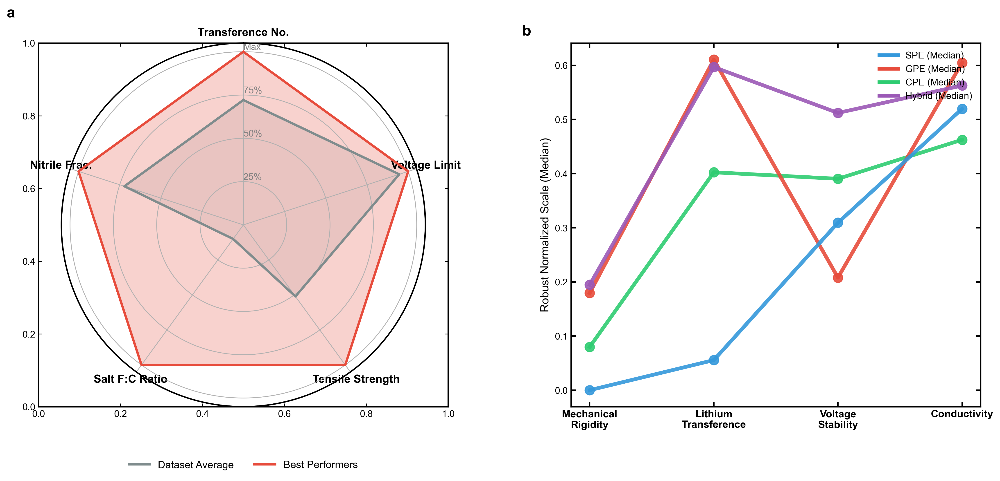

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from math import pi

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.subplots_adjust(wspace=0.3)

# ==========================================
# 0. Apply Architecture Logic & Color Palette
# ==========================================
conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

arch_palette = {'SPE': '#3498db',    
                'GPE': '#e74c3c',    
                'CPE': '#2ecc71',    
                'Hybrid': '#9b59b6'} 

# ==========================================
# --- 6A: Radar Chart (Multi-Objective Heroes) ---
# ==========================================
categories = ['Transference No.', 'Voltage Limit', 'Tensile Strength', 'Salt F:C Ratio', 'Nitrile Frac.']
N = len(categories)
radar_cols = ['transference_number', 'Voltage_Limit_V', 'Tensile_Strength_MPa', 'salt_F_to_C', 'poly_fr_nitrile_mean']

# Base dataset for radar: must have all physical descriptors
df_radar_clean = df.dropna(subset=radar_cols + ['log10_sigma']).copy()

# 1. THE FIX: Define true Ideal using multi-objective constraints
q80_sigma = df_radar_clean['log10_sigma'].quantile(0.80)
q50_tensile = df_radar_clean['Tensile_Strength_MPa'].quantile(0.50)

df_heroes = df_radar_clean[
    (df_radar_clean['log10_sigma'] >= q80_sigma) & 
    (df_radar_clean['Tensile_Strength_MPa'] >= q50_tensile) & 
    (df_radar_clean['transference_number'] >= 0.5)
]

val_avg, val_top5 = [], []

for col in radar_cols:
    mean_avg = df_radar_clean[col].mean()
    mean_top = df_heroes[col].mean() if len(df_heroes) > 0 else 0
    axis_max = max(mean_avg, mean_top)
    
    val_avg.append(mean_avg / axis_max if axis_max > 0 else 0)
    val_top5.append(mean_top / axis_max if axis_max > 0 else 0)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]
val_avg += val_avg[:1]
val_top5 += val_top5[:1]

ax_radar = plt.subplot(121, polar=True)
ax_radar.set_theta_offset(pi / 2)
ax_radar.set_theta_direction(-1)
plt.xticks(angles[:-1], categories, size=12, fontweight='bold')
ax_radar.set_rlabel_position(0)
plt.yticks([0.25, 0.5, 0.75, 1.0], ["25%", "50%", "75%", "Max"], color="grey", size=10)
plt.ylim(0, 1.05)

ax_radar.plot(angles, val_avg, linewidth=2.5, linestyle='solid', label='Dataset Average', color='#7f8c8d')
ax_radar.fill(angles, val_avg, '#7f8c8d', alpha=0.15)
ax_radar.plot(angles, val_top5, linewidth=2.5, linestyle='solid', label='Best Performers', color='#e74c3c')
ax_radar.fill(angles, val_top5, '#e74c3c', alpha=0.25)

ax_radar.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=11)
ax_radar.text(-0.15, 1.1, 'a', transform=ax_radar.transAxes, fontsize=16, fontweight='bold', va='top')


# ==========================================
# --- 6B: Parallel Coordinates Blueprint ---
# ==========================================
pc_cols = ['Tensile_Strength_MPa', 'transference_number', 'Voltage_Limit_V', 'log10_sigma']
df_pc = df.copy()

# strictly drop any rows where core electrochemical OR mechanical values are missing.
# We DO NOT impute synthetic data. We only plot verified experimental reports.
df_pc = df_pc.dropna(subset=['transference_number', 'Voltage_Limit_V', 'log10_sigma', 'Tensile_Strength_MPa', 'Architecture'])

df_pc_agg = df_pc.groupby('Architecture')[pc_cols].median().reset_index()

# Now strictly drop only if the core electrochemical values are missing
df_pc = df_pc.dropna(subset=['transference_number', 'Voltage_Limit_V', 'log10_sigma', 'Tensile_Strength_MPa', 'Architecture'])

df_pc_agg = df_pc.groupby('Architecture')[pc_cols].median().reset_index()

# Apply Robust Percentile Normalization to preserve the trade-offs
for col in pc_cols:
    clean_col = df_pc[col].dropna()
    g_min = clean_col.quantile(0.05)
    g_max = clean_col.quantile(0.95)
    if g_max > g_min:
        df_pc_agg[col] = (df_pc_agg[col] - g_min) / (g_max - g_min)
        df_pc_agg[col] = df_pc_agg[col].clip(lower=0.0, upper=1.0)

x_coords = [0, 1, 2, 3]

for _, row in df_pc_agg.iterrows():
    y_coords = row[pc_cols].values
    m_class = str(row['Architecture'])
    line_color = arch_palette.get(m_class, '#95a5a6')
    axes[1].plot(x_coords, y_coords, color=line_color, linewidth=4, marker='o', markersize=10, alpha=0.9)

x_labels = ['Mechanical\nRigidity', 'Lithium\nTransference', 'Voltage\nStability', 'Conductivity']
axes[1].set_xticks(x_coords)
axes[1].set_xticklabels(x_labels, fontweight='bold', fontsize=11)
axes[1].set_ylabel('Robust Normalized Scale (Median)')

legend_elements = [Line2D([0], [0], color=color, lw=4, label=f"{arch} (Median)") 
                   for arch, color in arch_palette.items() 
                   if arch in df_pc_agg['Architecture'].values]
axes[1].legend(handles=legend_elements, loc='upper right', title='', frameon=False)

def format_chem_mater(ax):
    ax.tick_params(direction='in', length=5, width=1.5, colors='k', 
                   top=True, right=True, bottom=True, left=True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_visible(True)

try:
    format_chem_mater(axes[1])
except NameError:
    pass

axes[1].text(-0.12, 1.05, 'b', transform=axes[1].transAxes, fontsize=16, fontweight='bold', va='top')

plt.savefig('figures/Figure_6_Design_Blueprint.png', dpi=300, bbox_inches='tight')
plt.show()

## Ignore this part below

Training GPR... (this may take a moment)
Optimized Kernel: 2.44**2 * Matern(length_scale=26.5, nu=1.5) + WhiteKernel(noise_level=0.679)


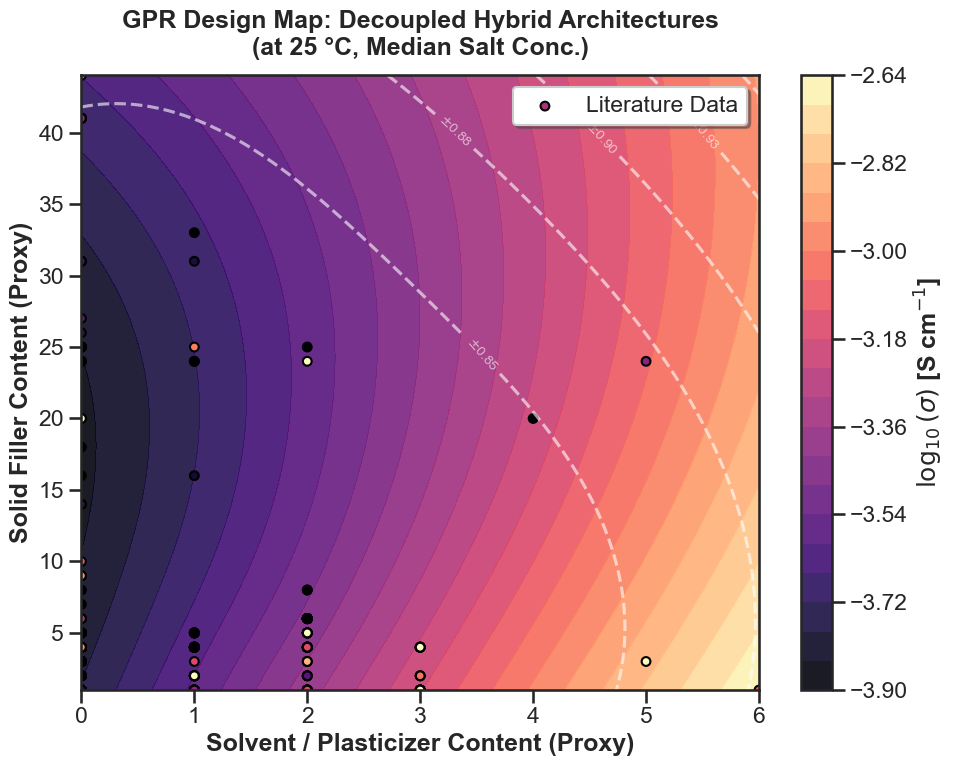

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler

# Set publication-quality aesthetics
sns.set_theme(style="ticks", context="talk")
plt.rcParams['font.family'] = 'sans-serif'

# --- 1. FILTER FOR DECOUPLED ARCHITECTURES ---
# Focus purely on systems containing active fillers (CPEs/Hybrids)
df_hybrid = df[(df['has_fill'] == 1) | (df['Material_Class_Short'] == 'CPE')].copy()

# Define the 4 continuous variables that dictate the physicochemical space
# If you have explicit weight % columns, replace solv_n_mols and fill_n_mols here:
features = ['solv_n_mols', 'fill_n_mols', 'molar_ratio', 'temperature_C']
target = 'log10_sigma'

# Drop NaNs for the model
df_gpr = df_hybrid.dropna(subset=features + [target])

X = df_gpr[features]
y = df_gpr[target].values

# --- 2. PREPROCESSING & GPR TRAINING ---
# GPR is incredibly sensitive to distance, so scaling is mandatory
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define the Kernel: 
# Matern 5/2 handles the non-linear physics. WhiteKernel absorbs the literature reporting noise.
kernel = ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=0.1)

# Initialize and fit the GPR
print("Training GPR... (this may take a moment)")
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=42, alpha=0.0)
gpr.fit(X_scaled, y)
print(f"Optimized Kernel: {gpr.kernel_}")

# --- 3. GENERATE THE 2D DESIGN MAP (GRID) ---
# We will create a 2D grid of Solvent vs. Filler content
# while locking Salt Concentration to its median and Temperature to 25 deg C.

grid_size = 100
# Create linear spaces for the X and Y axes of our contour plot
f1_vals = np.linspace(X['solv_n_mols'].min(), X['solv_n_mols'].max(), grid_size)
f2_vals = np.linspace(X['fill_n_mols'].min(), X['fill_n_mols'].max(), grid_size)

F1, F2 = np.meshgrid(f1_vals, f2_vals)

# Create the test matrix. Fill with our grid, and lock the other two variables
X_grid = pd.DataFrame({
    'solv_n_mols': F1.ravel(),
    'fill_n_mols': F2.ravel(),
    'molar_ratio': np.median(X['molar_ratio']), # Locked at median salt concentration
    'temperature_C': 25.0                       # Locked at Room Temperature
})

X_grid_scaled = scaler.transform(X_grid)

# Predict conductivity AND the uncertainty (standard deviation)
y_pred, y_std = gpr.predict(X_grid_scaled, return_std=True)

# Reshape back to grid for plotting
Z_pred = y_pred.reshape(grid_size, grid_size)
Z_std = y_std.reshape(grid_size, grid_size)

# --- 4. PLOT THE DESIGN MAP ---
fig, ax = plt.subplots(figsize=(10, 8))

# Contour fill for predicted conductivity
contour = ax.contourf(F1, F2, Z_pred, levels=20, cmap='magma', alpha=0.9)
cbar = plt.colorbar(contour, ax=ax)
cbar.set_label(r'$\log_{10}(\sigma)$ [S cm$^{-1}$]', fontweight='bold')

# Overlay contours for Uncertainty (Reviewers LOVE this)
# Dashed lines represent areas where the model is guessing due to lack of experimental data
std_contour = ax.contour(F1, F2, Z_std, levels=5, colors='white', linestyles='dashed', alpha=0.6)
ax.clabel(std_contour, inline=True, fontsize=10, fmt='$\pm$%.2f')

# Scatter the actual literature data points on top to show where experiments have actually been done
scatter = ax.scatter(X['solv_n_mols'], X['fill_n_mols'], 
                     c=y, cmap='magma', edgecolors='black', 
                     s=40, vmin=Z_pred.min(), vmax=Z_pred.max(), label='Literature Data')

ax.set_xlabel('Solvent / Plasticizer Content (Proxy)', fontweight='bold')
ax.set_ylabel('Solid Filler Content (Proxy)', fontweight='bold')
ax.set_title('GPR Design Map: Decoupled Hybrid Architectures\n(at 25 °C, Median Salt Conc.)', fontweight='bold', pad=15)
ax.legend(loc='upper right', frameon=True, shadow=True)

plt.tight_layout()
plt.show()

Training GPR... (this may take a moment)
Optimized Kernel: 2.44**2 * Matern(length_scale=26.5, nu=1.5) + WhiteKernel(noise_level=0.679)


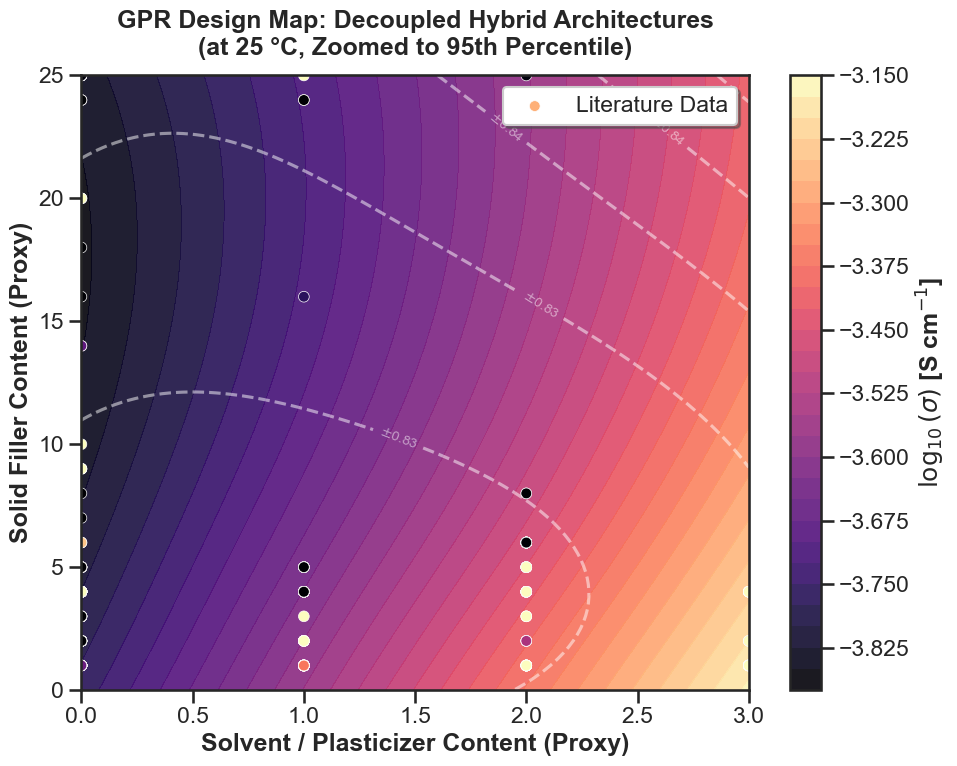

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler

# Set publication-quality aesthetics
sns.set_theme(style="ticks", context="talk")
plt.rcParams['font.family'] = 'sans-serif'

# --- 1. FILTER FOR DECOUPLED ARCHITECTURES ---
df_features = pd.read_csv('SPE_dataset_v6_reduced.csv') 

# (Tg_C, activation_energy_eV, Tensile_Strength_MPa, Current_Density_mA_cm2, Lifetime_Hours, etc.)
df_targets = pd.read_csv('SPE_Dataset_ML_Ready_v2.csv') 

df = pd.merge(
    df_features, 
    df_targets[['source.doi', 'Tg_C', 'activation_energy_eV', 'Tensile_Strength_MPa', 
                'Current_Density_mA_cm2', 'Lifetime_Hours', 'Voltage_Limit_V', 'transference_number']], 
    on='source.doi', 
    how='inner'
)

class_map = {
    'Solid Polymer Electrolyte (SPE)': 'SPE',
    'Gel Polymer Electrolyte (GPE)': 'GPE',
    'Composite Polymer Electrolyte (CPE)': 'CPE'
}
df['Material_Class_Short'] = df['Material_Class'].map(class_map).fillna('Other')


df = df.dropna(subset=['log10_sigma'])

# Focus purely on systems containing active fillers (CPEs/Hybrids)
df_hybrid = df[(df['has_fill'] == 1) | (df['Material_Class_Short'] == 'CPE')].copy()

# Define the 4 continuous variables that dictate the physicochemical space
# If you have explicit weight % columns, replace solv_n_mols and fill_n_mols here:
features = ['solv_n_mols', 'fill_n_mols', 'molar_ratio', 'temperature_C']
target = 'log10_sigma'

# Drop NaNs for the model
df_gpr = df_hybrid.dropna(subset=features + [target])

X = df_gpr[features]
y = df_gpr[target].values

# --- 2. PREPROCESSING & GPR TRAINING ---
# GPR is incredibly sensitive to distance, so scaling is mandatory
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define the Kernel: 
# Matern 5/2 handles the non-linear physics. WhiteKernel absorbs the literature reporting noise.
kernel = ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=0.1)

# Initialize and fit the GPR
print("Training GPR... (this may take a moment)")
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=42, alpha=0.0)
gpr.fit(X_scaled, y)
print(f"Optimized Kernel: {gpr.kernel_}")

# --- 3. GENERATE THE 2D DESIGN MAP (ZOOMED IN) ---
grid_size = 100

# FIX: Use the 95th percentile to ignore extreme outliers and zoom in on the real data
max_solv = np.percentile(X['solv_n_mols'], 95)
max_fill = np.percentile(X['fill_n_mols'], 95)

# Create linear spaces that ONLY span the dense, realistic formulation space
f1_vals = np.linspace(0, max_solv, grid_size)
f2_vals = np.linspace(0, max_fill, grid_size)

F1, F2 = np.meshgrid(f1_vals, f2_vals)

# Create the test matrix
X_grid = pd.DataFrame({
    'solv_n_mols': F1.ravel(),
    'fill_n_mols': F2.ravel(),
    'molar_ratio': np.median(X['molar_ratio']), 
    'temperature_C': 25.0                       
})

X_grid_scaled = scaler.transform(X_grid)
y_pred, y_std = gpr.predict(X_grid_scaled, return_std=True)

Z_pred = y_pred.reshape(grid_size, grid_size)
Z_std = y_std.reshape(grid_size, grid_size)

# --- 4. PLOT THE DESIGN MAP ---
fig, ax = plt.subplots(figsize=(10, 8))

# Contour fill for predicted conductivity
contour = ax.contourf(F1, F2, Z_pred, levels=30, cmap='magma', alpha=0.9)
cbar = plt.colorbar(contour, ax=ax)
cbar.set_label(r'$\log_{10}(\sigma)$ [S cm$^{-1}$]', fontweight='bold')

# Uncertainty overlay
std_contour = ax.contour(F1, F2, Z_std, levels=5, colors='white', linestyles='dashed', alpha=0.5)
ax.clabel(std_contour, inline=True, fontsize=10, fmt='$\pm$%.2f')

# Filter the scatter points so we only plot the ones inside our new zoomed-in box
mask = (X['solv_n_mols'] <= max_solv) & (X['fill_n_mols'] <= max_fill)
ax.scatter(X.loc[mask, 'solv_n_mols'], X.loc[mask, 'fill_n_mols'], 
           c=y[mask], cmap='magma', edgecolors='white', linewidths=0.5,
           s=60, vmin=Z_pred.min(), vmax=Z_pred.max(), label='Literature Data')

ax.set_xlabel('Solvent / Plasticizer Content (Proxy)', fontweight='bold')
ax.set_ylabel('Solid Filler Content (Proxy)', fontweight='bold')
ax.set_title('GPR Design Map: Decoupled Hybrid Architectures\n(at 25 °C, Zoomed to 95th Percentile)', fontweight='bold', pad=15)
ax.legend(loc='upper right', frameon=True, shadow=True)

plt.tight_layout()
plt.show()

In [6]:

dois = df['source.doi'].dropna().unique()

with open("Master_DOI_List.txt", "w") as f:
    for doi in dois:
        f.write(f"{doi}\n")
